# Sample-wise Double Descent in Minimum-Norm Least Squares

**Double descent** is a phenomenon where the test error first decreases as model complexity grows, then rises sharply near the *interpolation threshold* (where the model can just fit the training data perfectly), and then decreases again as complexity keeps growing. For neural networks it is still not fully understood, but it can already be observed, and explained, in the simplest possible model: ordinary least squares (OLS).

In this notebook I study **sample-wise double descent**: the number of features $d$ is kept fixed and the number of training points $n$ is varied. When $n < d$ the system is underdetermined, so I use the **minimum-norm** OLS solution.

**Questions:**
1. Does sample-wise double descent appear for OLS on synthetic data?
2. Which properties of the dataset (dimension, noise level, feature distribution) control it?
3. What mechanism explains the peak?

**Contents:** (1) OLS and the minimum-norm solution, with derivation; (2) conditioning; (3) a first experiment; (4) a 1,000-run Monte Carlo study; (5) the effect of the noise level; (6) Gaussian instead of uniform features; (7) conclusions.

*Runtime: about one minute on a laptop.*

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Ordinary least squares

We are going to first define the Ordinary Least Squares (OLS) method:
* Loss function: $J(w) = \frac{1}{n} \| Xw - y \|^2_{2}$

Computing the gradient with respect to $w$ we obtain the normal equations: $X^\top Xw = X^\top y$

To solve this linear system we never compute the inverse of the matrix explicitly: computing an inverse costs more ($\sim 2m^3$ operations for a dense $m \times m$ matrix) and is numerically less stable than solving the system through a factorization. We can use either the LU factorization, $\sim \frac{2}{3}m^3$ operations (with partial pivoting, which guarantees that the factors $L$ and $U$ exist for any invertible matrix), or the Cholesky factorization, $\sim \frac{1}{3}m^3$ operations (which requires more assumptions, but is twice as fast as LU).

The matrix $X^\top X$ is always symmetric positive semidefinite. To apply Cholesky we need it to be positive definite, i.e. $X$ must have full column rank. This holds almost surely for our data: the entries of $X \in \mathbb{R}^{n\times d}$ are drawn from a continuous distribution, and rank-deficient matrices form a set of measure zero.

However, since the goal here is to study a phenomenon, and not to implement a linear solver, we use NumPy's native function `np.linalg.solve`, which solves the system with an LU factorization with partial pivoting. Our systems are small (at most $60 \times 60$), so the cost is not an issue.

In [2]:
def OLS_np(X, y):
    """Least squares with np.linalg; minimum-norm solution when n < d."""
    n, d = X.shape
    if n >= d:
        return np.linalg.solve(X.T @ X, X.T @ y)   # (X^T X) w = X^T y
    else:
        alpha = np.linalg.solve(X @ X.T, y)        # (X X^T) alpha = y
        return X.T @ alpha                         # w = X^T alpha

## 2. Minimum-norm solution and conditioning

Since the system can be both underdetermined ($n<d$) and overdetermined ($n \ge d$), the OLS function needs to handle both cases.

**Case $n \ge d$.** If $X$ has full column rank $d$ (true almost surely for continuous random data), then $X^\top X \in \mathbb{R}^{d\times d}$ is symmetric positive definite, so the normal equations $X^\top X w = X^\top y$ have a unique solution.

**Case $n < d$.** The rank of $X$ is at most $n$, so $Xw = y$ has infinitely many solutions (a $(d-n)$-dimensional affine set). Among them we take the one with minimum Euclidean norm:

$$\min_{w}\ \tfrac12\|w\|_2^2 \quad \text{s.t.}\quad Xw = y .$$

Lagrangian, with multiplier $\alpha \in \mathbb{R}^n$:
$$\mathcal{L}(w,\alpha) = \tfrac12 w^\top w - \alpha^\top (Xw - y).$$

Stationarity in $w$: $\ \nabla_w \mathcal{L} = w - X^\top \alpha = 0 \ \Rightarrow\ w = X^\top \alpha$.

Substituting into the constraint: $\ X X^\top \alpha = y$. Since $\operatorname{rank}(X)=n$, the $n\times n$ matrix $XX^\top$ is symmetric positive definite, hence invertible:
$$\alpha = (XX^\top)^{-1} y, \qquad w_{\min} = X^\top (XX^\top)^{-1} y .$$

The objective is strictly convex and the constraint is linear, so this is the unique global minimizer.
In other words, we proved that $w = X^+ y$, with $X^+$ the Moore–Penrose pseudoinverse of $X$, is the minimum-norm solution of $Xw = y$.

**Conditioning.** Since we are solving linear systems, it is important to check how well-conditioned they are. A matrix with a high condition number $\kappa(A)$ is close to singular, so small perturbations in the data can cause large changes in the solution. In the 2-norm:
$$\kappa_2(A) = \|A\|_2\,\|A^{-1}\|_2 = \frac{s_{\max}(A)}{s_{\min}(A)},$$
where $s_{\max}, s_{\min}$ are the largest and smallest singular values. For a rectangular matrix such as $X$, which has no inverse, we use the same ratio $\kappa_2(X) = s_{\max}(X)/s_{\min}(X)$ (equivalently, $\|X\|_2\,\|X^+\|_2$).

For $n < d$, the $d\times d$ matrix $X^\top X$ has $d-n$ zero eigenvalues, so it is singular and $\kappa(X^\top X)=\infty$. However, that is not the matrix we solve with in this case: for $n<d$ we solve with $XX^\top$, and for $n\ge d$ with $X^\top X$. In both cases
$$\kappa_2(XX^\top) = \kappa_2(X^\top X) = \kappa_2(X)^2 \quad \text{(on the side where the matrix is invertible)},$$
so we compute $\kappa_2(X)$ with `np.linalg.cond(X)` (via SVD) and square it. This quantity is finite for every $n$ and $d$, and computing it from $X$ directly avoids forming $X^\top X$ or $XX^\top$, which would itself square the conditioning in floating point.

We compute this quantity both in the first experiment and in the Monte Carlo simulation, to investigate whether, and how, the phenomenon is related to the conditioning of the problem.

## 3. A first experiment

In the next code, we implement a first simulation to show that **sample-wise double descent** occurs in this framework: OLS (minimum-norm when $n<d$), uniformly generated data and weights, and Gaussian noise.



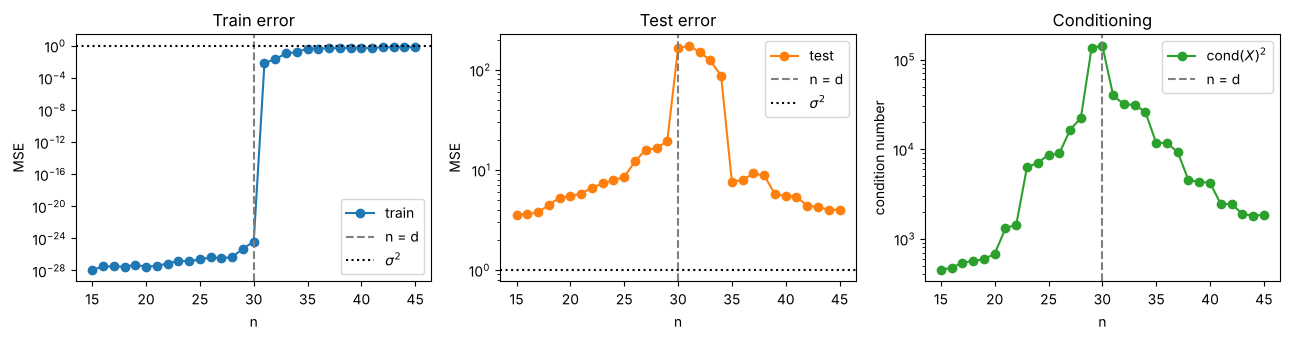

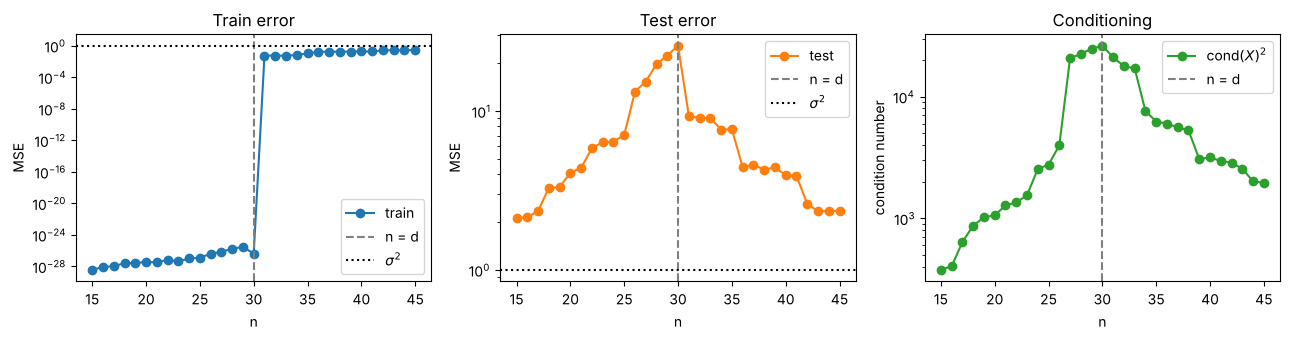

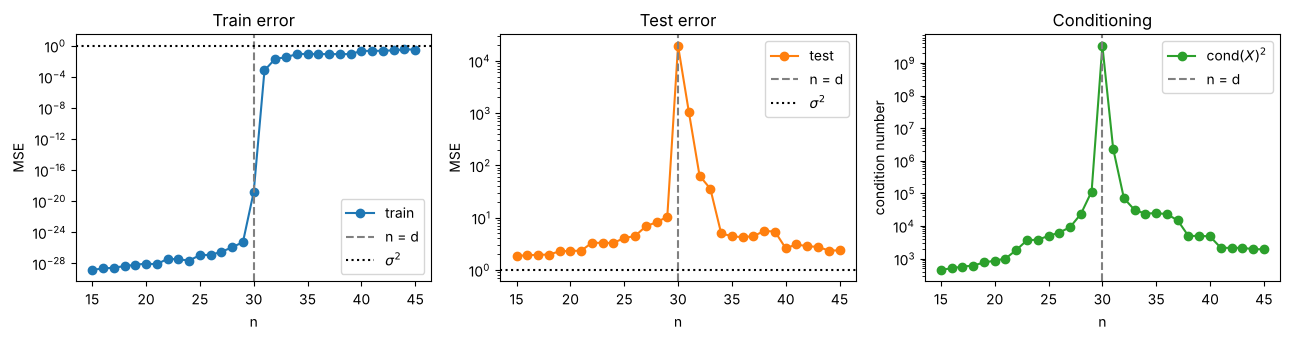

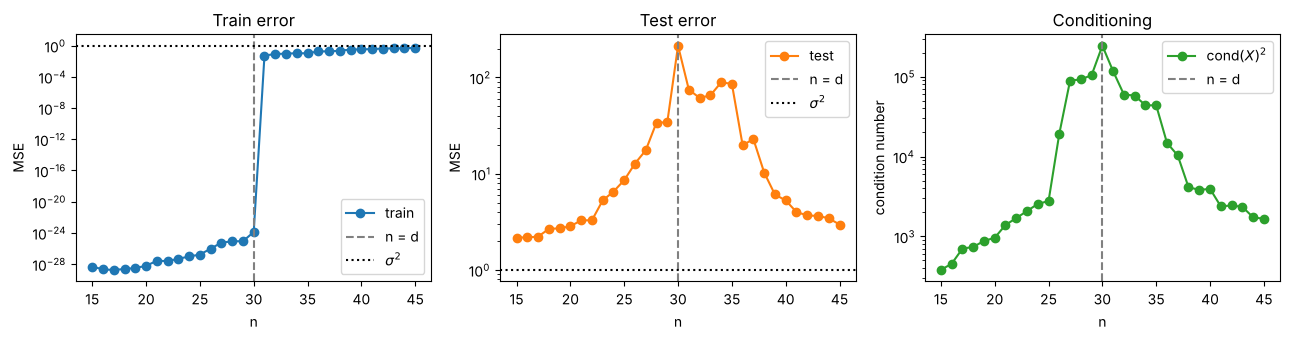

In [3]:
d = 30
sigma = 1.0
n_test = 1000
for i in range(4):
    rng = np.random.default_rng(seed=i)
    w_in = rng.uniform(0, 1, size=d)

    # starting training set: n = d/2
    X_train = rng.uniform(0, 1, size=(d // 2, d))
    y_train = X_train @ w_in + rng.normal(0, sigma, size=d // 2)

    # fixed test set
    X_test = rng.uniform(0, 1, size=(n_test, d))
    y_test = X_test @ w_in + rng.normal(0, sigma, size=n_test)

    ns, train_err, test_err, k = [], [], [] , []

    for step in range(d + 1):                    # n from d/2 to d + d/2
        w = OLS_np(X_train, y_train)
        ns.append(X_train.shape[0])
        train_err.append(np.mean((X_train @ w - y_train) ** 2))
        test_err.append(np.mean((X_test @ w - y_test)**2))
       
        # squared condition number kappa(X)^2 = kappa(X^T X), for the CURRENT X
        k.append(np.linalg.cond(X_train)**2)
        
        # add one new point
        u = rng.uniform(0, 1, size=d)
        X_train = np.vstack([X_train, u])
        y_train = np.append(y_train, u @ w_in + rng.normal(0, sigma))

        
    
    ns = np.array(ns)

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharex=True)
    # Train error
    ax = axes[0]
    ax.plot(ns, train_err, "o-", label="train")
    ax.axvline(d, color="gray", linestyle="--", label="n = d")
    ax.axhline(sigma**2, color="black", linestyle=":", label=r"$\sigma^2$")
    ax.set_yscale("log")
    ax.set_xlabel("n"); ax.set_ylabel("MSE"); ax.set_title("Train error")
    ax.legend()

    # Test error
    ax = axes[1]
    ax.plot(ns, test_err, "o-", color="tab:orange", label="test")
    ax.axvline(d, color="gray", linestyle="--", label="n = d")
    ax.axhline(sigma**2, color="black", linestyle=":", label=r"$\sigma^2$")
    ax.set_yscale("log")
    ax.set_xlabel("n"); ax.set_ylabel("MSE"); ax.set_title("Test error")
    ax.legend()

    # Condition number
    ax = axes[2]
    ax.plot(ns, k, "o-", color="tab:green", label=r"cond$(X)^2$")
    ax.axvline(d, color="gray", linestyle="--", label="n = d")
    ax.set_yscale("log")
    ax.set_xlabel("n"); ax.set_ylabel("condition number"); ax.set_title("Conditioning")
    ax.legend()

    fig.tight_layout()
    plt.show()



## 4. Monte Carlo study

In the first simulation we observe a spike of the test error close to $n = d$. We now want to verify that this phenomenon is not an artefact of the particular dataset generated in the first simulation. To do so, we repeat the experiment for many different random seeds: each seed produces a new true weight vector $w^*$, a new training set, a new test set and new noise realisations. (The effect of the noise level $\sigma$ is studied separately afterwards.)

Moreover, we observe that the matrix $X$ becomes ill-conditioned when $n \approx d$: its smallest singular value $s_{\min}(X)$ approaches zero, so $\kappa(X)^2 = \kappa(X^\top X)$ becomes very large. The spike could therefore be either *generated* or *amplified* by this ill-conditioning. To investigate this, we also compute $\kappa(X)^2$ in the Monte Carlo simulation and compare it with the test error as a function of $n$.



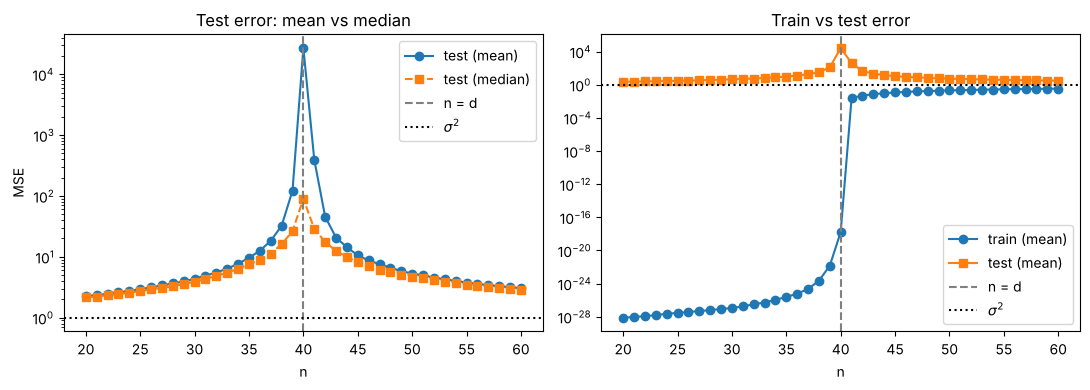

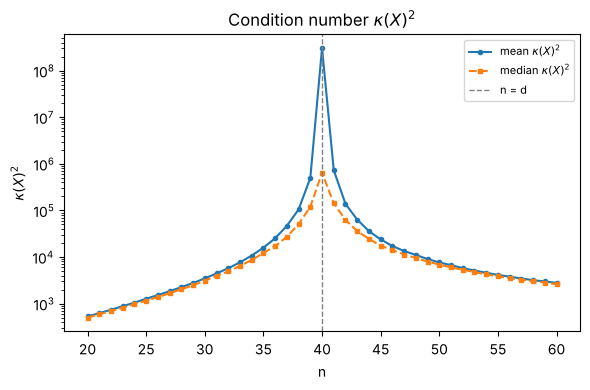

In [4]:
# Monte Carlo simulation: check that the results of the first simulation are not linked to a specific dataset

d = 40
sigma = 1
n_test = 1000
Mtrain_err, Mtest_err = [], []
Mkappa2 = []                    
for i in range(1000):
    rng = np.random.default_rng(seed=i)
    w_in = rng.uniform(0, 1, size=d)
    
    # starting training set: n = d/2
    X_train = rng.uniform(0, 1, size=(d // 2, d))
    y_train = X_train @ w_in + rng.normal(0, sigma, size=d // 2)

    # fixed test set
    X_test = rng.uniform(0, 1, size=(n_test, d))
    y_test = X_test @ w_in + rng.normal(0, sigma, size=n_test)

    ns, train_err, test_err = [], [], []
    kappa2 = []                   

    for step in range(d + 1):                       # n from d/2 to d + d/2
        w = OLS_np(X_train, y_train)
        ns.append(X_train.shape[0])
        train_err.append(np.mean((X_train @ w - y_train) ** 2)) 
        test_err.append(np.mean((X_test @ w - y_test)**2))

        # squared condition number kappa(X)^2 = kappa(X^T X), for the CURRENT X
        kappa2.append(np.linalg.cond(X_train)**2)                           

        # add one new point
        u = rng.uniform(0, 1, size=d)
        X_train = np.vstack([X_train, u])
        y_train = np.append(y_train, u @ w_in + rng.normal(0, sigma))

    Mtrain_err.append(train_err)
    Mtest_err.append(test_err)
    Mkappa2.append(kappa2)                       

Mtrain_err_np = np.array(Mtrain_err) 
Mtest_err_np  = np.array(Mtest_err)
Mkappa2_np    = np.array(Mkappa2)                          

train_mean  = np.nanmean(Mtrain_err_np, axis=0)
test_mean   = np.nanmean(Mtest_err_np, axis=0)
test_median = np.nanmedian(Mtest_err_np, axis=0)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)

# Left: mean vs median of the test error
ax = axes[0]
ax.plot(ns, test_mean, "o-", label="test (mean)")
ax.plot(ns, test_median, "s--", label="test (median)")
ax.axvline(d, color="gray", linestyle="--", label="n = d")
ax.axhline(sigma**2, color="black", linestyle=":", label=r"$\sigma^2$")
ax.set_yscale("log")
ax.set_xlabel("n"); ax.set_ylabel("MSE")
ax.set_title("Test error: mean vs median")
ax.legend()

# Right: train vs test (mean)
ax = axes[1]
ax.plot(ns, train_mean, "o-", label="train (mean)")
ax.plot(ns, test_mean, "s-", label="test (mean)")
ax.axvline(d, color="gray", linestyle="--", label="n = d")
ax.axhline(sigma**2, color="black", linestyle=":", label=r"$\sigma^2$")
ax.set_yscale("log")
ax.set_xlabel("n")
ax.set_title("Train vs test error")
ax.legend()

fig.tight_layout()
plt.show()

ns_arr = np.array(ns)

# Plot of the mean and median of the squared condition numbers
kappa2_mean   = np.mean(Mkappa2_np, axis=0)
kappa2_median = np.median(Mkappa2_np, axis=0)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(ns_arr, kappa2_mean,   "o-",  ms=3, label=r"mean $\kappa(X)^2$")
ax.plot(ns_arr, kappa2_median, "s--", ms=3, label=r"median $\kappa(X)^2$")
ax.axvline(d, color="gray", ls="--", lw=1, label="n = d")
ax.set_yscale("log")
ax.set_xlabel("n"); ax.set_ylabel(r"$\kappa(X)^2$")
ax.set_title(r"Condition number $\kappa(X)^2$")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 5. Effect of the noise level

As we can see, the Monte Carlo simulation shows that sample-wise double descent exists, and that it is correlated with the condition number.
In order to find which properties of the dataset influence the phenomenon, we are going to check:
1) What happens if the standard deviation $\sigma$ of the Gaussian noise changes?
2) What happens if, instead of building $X$ from a uniform distribution, we use a Gaussian distribution? Is the dependence on the noise level still present?


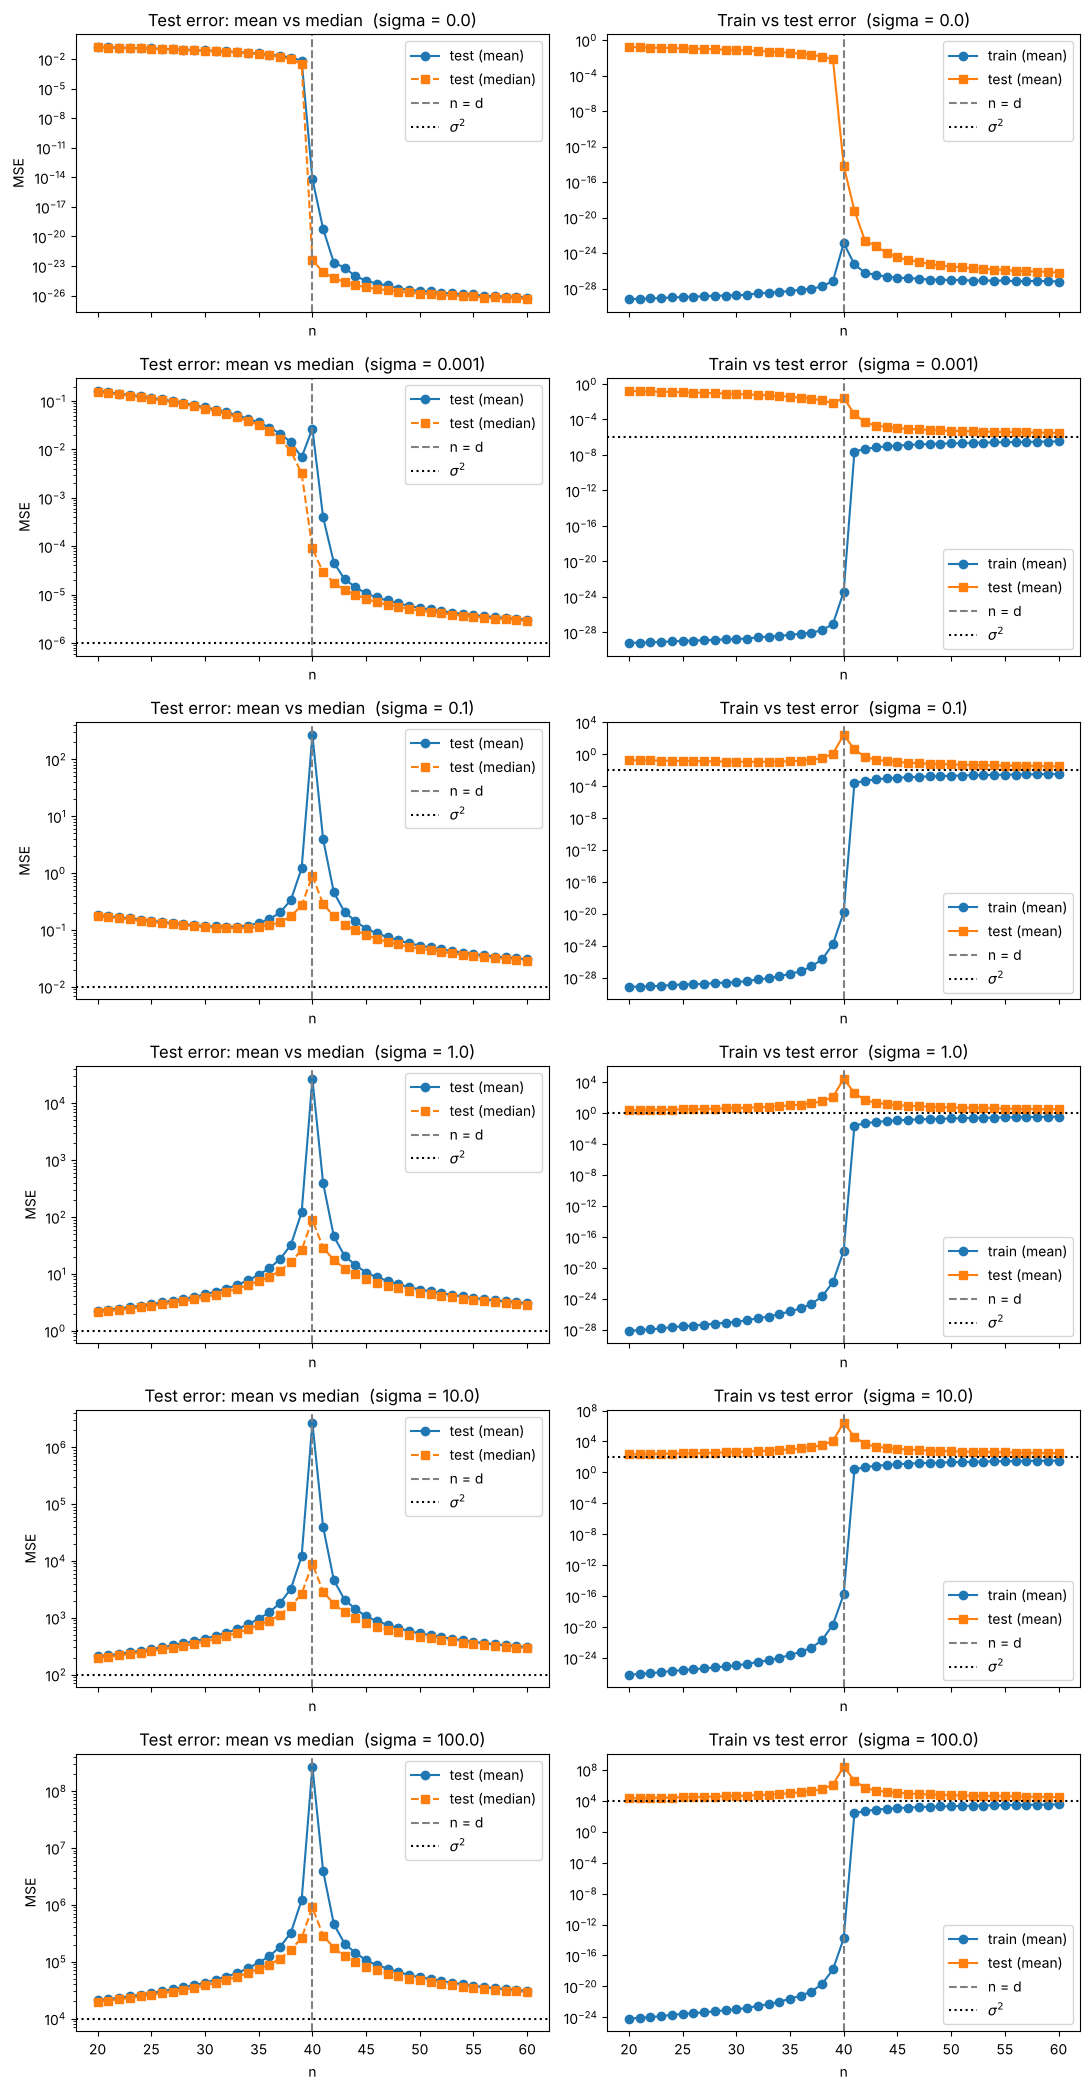

In [5]:
results = {}
sigma_values = np.array([0, 0.001, 0.1, 1, 10, 100])   # noise standard deviations

for sigma in sigma_values:
    d = 40
    n_test = 1000
    Mtrain_err, Mtest_err = [], []
    for i in range(1000):
        rng = np.random.default_rng(seed=i)
        w_in = rng.uniform(0, 1, size=d)
        
        # starting training set: n = d/2
        X_train = rng.uniform(0, 1, size=(d // 2, d))
        y_train = X_train @ w_in + rng.normal(0, sigma, size=d // 2)

        # fixed test set
        X_test = rng.uniform(0, 1, size=(n_test, d))
        y_test = X_test @ w_in + rng.normal(0, sigma, size=n_test)

        ns, train_err, test_err = [], [], []

        for step in range(d + 1):                       # n from d/2 to d + d/2
            w = OLS_np(X_train, y_train)
            ns.append(X_train.shape[0])
            train_err.append(np.mean((X_train @ w - y_train) ** 2))
            test_err.append(np.mean((X_test @ w - y_test)**2))

            # add one new point
            u = rng.uniform(0, 1, size=d)
            X_train = np.vstack([X_train, u])
            y_train = np.append(y_train, u @ w_in + rng.normal(0, sigma))

        Mtrain_err.append(train_err)
        Mtest_err.append(test_err)

    Mtrain_err_np = np.array(Mtrain_err)   # shape (M, len(ns))
    Mtest_err_np  = np.array(Mtest_err)

    train_mean  = np.nanmean(Mtrain_err_np, axis=0)
    test_mean   = np.nanmean(Mtest_err_np, axis=0)
    test_median = np.nanmedian(Mtest_err_np, axis=0)

    results[sigma] = {
        "ns": np.array(ns),
        "train_mean": train_mean,
        "test_mean": test_mean,
        "test_median": test_median,
        "M": Mtest_err_np.shape[0],
    }


# ---------- Figures: one row per sigma ----------
sigmas = list(results.keys())
fig, axes = plt.subplots(len(sigmas), 2, figsize=(11, 3.5 * len(sigmas)), sharex=True)

for r, sigma in enumerate(sigmas):
    res = results[sigma]
    ns = res["ns"]

    # Left: mean vs median of the test error
    ax = axes[r, 0]
    ax.plot(ns, res["test_mean"], "o-", label="test (mean)")
    ax.plot(ns, res["test_median"], "s--", label="test (median)")
    ax.axvline(d, color="gray", linestyle="--", label="n = d")
    ax.axhline(sigma**2, color="black", linestyle=":", label=r"$\sigma^2$")
    ax.set_yscale("log")
    ax.set_xlabel("n"); ax.set_ylabel("MSE")
    ax.set_title(f"Test error: mean vs median  (sigma = {sigma})")
    ax.legend()

    # Right: train vs test (mean)
    ax = axes[r, 1]
    ax.plot(ns, res["train_mean"], "o-", label="train (mean)")
    ax.plot(ns, res["test_mean"], "s-", label="test (mean)")
    ax.axvline(d, color="gray", linestyle="--", label="n = d")
    ax.axhline(sigma**2, color="black", linestyle=":", label=r"$\sigma^2$")
    ax.set_yscale("log")
    ax.set_xlabel("n")
    ax.set_title(f"Train vs test error  (sigma = {sigma})")
    ax.legend()

fig.tight_layout()
plt.show()

Summary: the mean test error for every noise level on a single plot. The peak is always at $n = d$, and its height scales with $\sigma^2$.

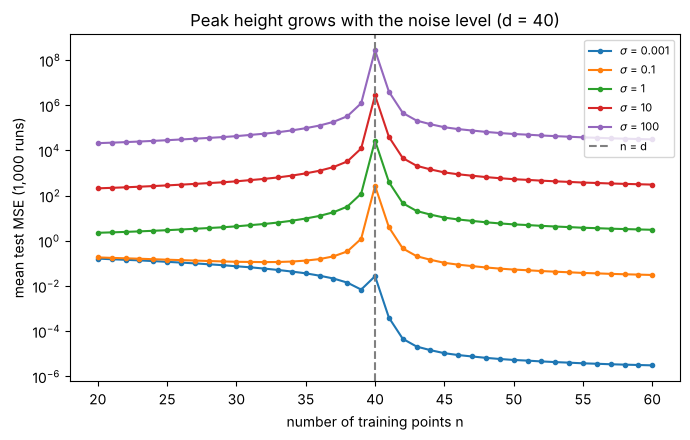

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for sigma in sigma_values:
    if sigma == 0:
        continue                      # zero test error for n >= d: cannot be shown on a log scale
    res = results[sigma]
    ax.plot(res["ns"], res["test_mean"], "o-", ms=3, label=rf"$\sigma$ = {sigma:g}")
ax.axvline(d, color="gray", linestyle="--", label="n = d")
ax.set_yscale("log")
ax.set_xlabel("number of training points n")
ax.set_ylabel("mean test MSE (1,000 runs)")
ax.set_title(f"Peak height grows with the noise level (d = {d})")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 6. Gaussian features

Next, we drop the assumption of building the dataset from a uniform distribution, and we sample from the independent standard normal distribution $N(0,1)$ (now with $d = 60$). We will see that the spikes remain visually the same: the errors change in value, but the phenomenon is still there. Moreover, we check whether the phenomenon still depends on the noise level in the same way.

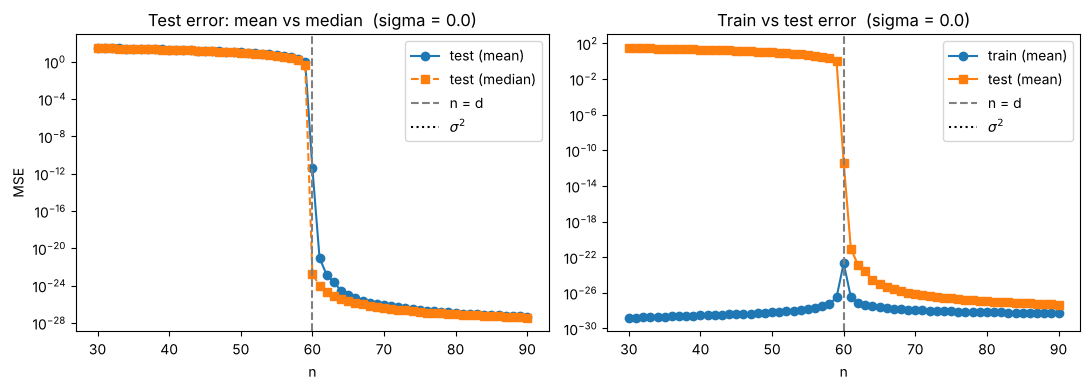

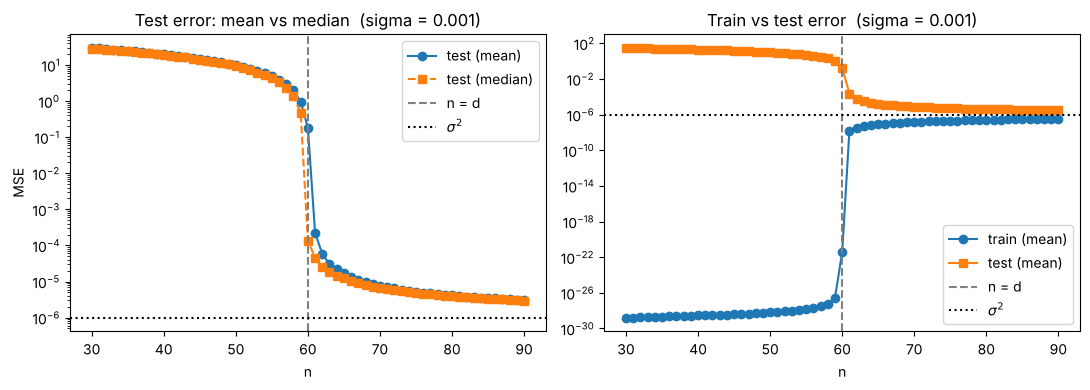

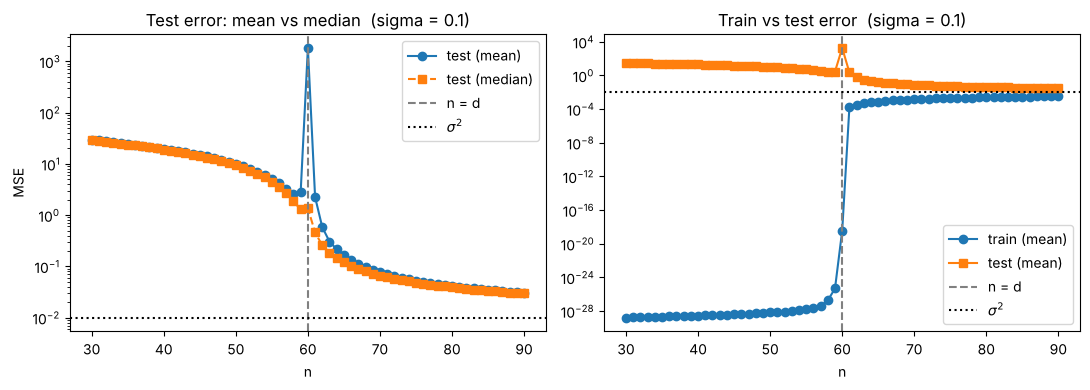

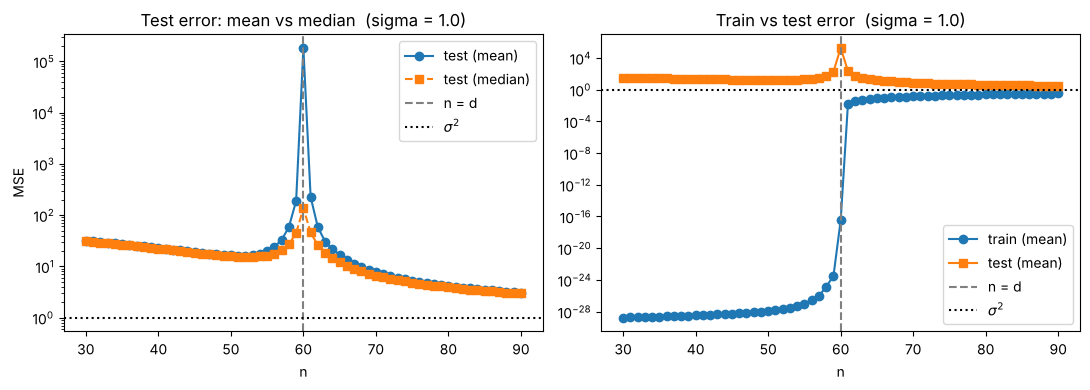

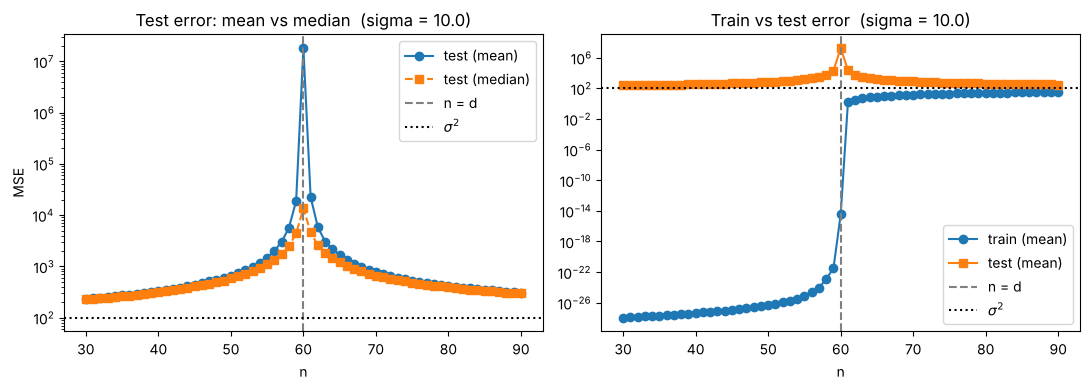

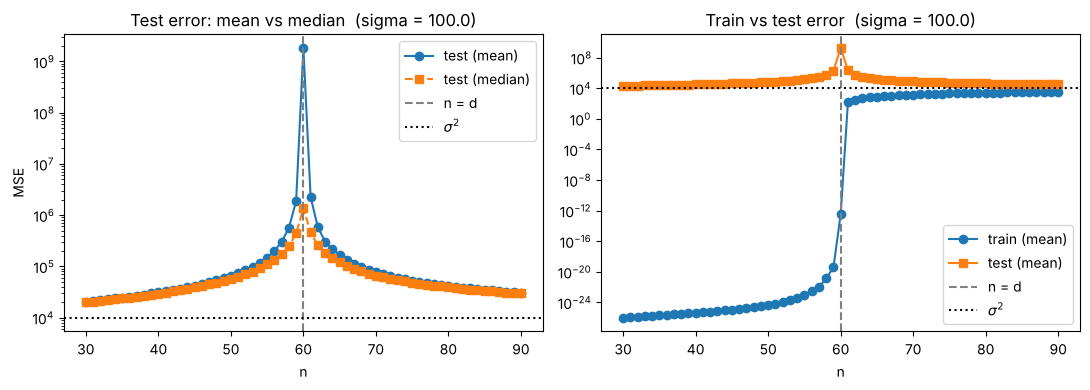

In [7]:
# Monte Carlo simulation with Gaussian features N(0,1)

sigma_values = np.array([0, 0.001, 0.1, 1, 10, 100])   # noise standard deviations

for sigma in sigma_values:
    d = 60
    n_test = 1000
    Mtrain_err, Mtest_err = [], []
    for i in range(1000):
        rng = np.random.default_rng(seed=i)
        w_in = rng.standard_normal(d)

        # starting training set: n = d/2
        X_train = rng.standard_normal((d // 2, d))
        y_train = X_train @ w_in + rng.normal(0, sigma, size=d // 2)

        # fixed test set
        X_test = rng.standard_normal((n_test, d))
        y_test = X_test @ w_in + rng.normal(0, sigma, size=n_test)

        ns, train_err, test_err = [], [], []

        for step in range(d + 1):                       # n from d/2 to d + d/2
            w = OLS_np(X_train, y_train)
            ns.append(X_train.shape[0])
            train_err.append(np.mean((X_train @ w - y_train) ** 2)) 
            test_err.append(np.mean((X_test @ w - y_test)**2))

            # add one new point
            u = rng.standard_normal(d)
            X_train = np.vstack([X_train, u])
            y_train = np.append(y_train, u @ w_in + rng.normal(0, sigma))

        Mtrain_err.append(train_err)
        Mtest_err.append(test_err)

    Mtrain_err_np = np.array(Mtrain_err)   # shape (M, len(ns))
    Mtest_err_np  = np.array(Mtest_err)

    train_mean  = np.nanmean(Mtrain_err_np, axis=0)
    test_mean   = np.nanmean(Mtest_err_np, axis=0)
    test_median = np.nanmedian(Mtest_err_np, axis=0)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True)

    # Left: mean vs median of the test error
    ax = axes[0]
    ax.plot(ns, test_mean, "o-", label="test (mean)")
    ax.plot(ns, test_median, "s--", label="test (median)")
    ax.axvline(d, color="gray", linestyle="--", label="n = d")
    ax.axhline(sigma**2, color="black", linestyle=":", label=r"$\sigma^2$")
    ax.set_yscale("log")
    ax.set_xlabel("n"); ax.set_ylabel("MSE")
    ax.set_title(f"Test error: mean vs median  (sigma = {sigma})")
    ax.legend()

    # Right: train vs test (mean)
    ax = axes[1]
    ax.plot(ns, train_mean, "o-", label="train (mean)")
    ax.plot(ns, test_mean, "s-", label="test (mean)")
    ax.axvline(d, color="gray", linestyle="--", label="n = d")
    ax.axhline(sigma**2, color="black", linestyle=":", label=r"$\sigma^2$")
    ax.set_yscale("log")
    ax.set_xlabel("n")
    ax.set_title(f"Train vs test error  (sigma = {sigma})")
    ax.legend()

    fig.tight_layout()
    plt.show()

## 7. Conclusions

In all our experiments, the train and test errors as functions of the number of training points $n$ (with $d$ fixed) behave as follows:
* **Train error:** it is zero (up to round-off) for $n \le d$, because the minimum-norm solution interpolates the training data exactly. For $n > d$ the model can no longer fit every point, and the train error increases towards the noise level $\sigma^2$.
* **Test error:** for $n < d$ it increases as $n$ approaches $d$ (adding data makes the model worse), it reaches a sharp peak at the interpolation threshold $n = d$, and for $n > d$ it decreases again towards $\sigma^2$. This is sample-wise double descent.
* **Mean vs median:** the peak is much higher in the mean than in the median over the Monte Carlo repetitions. The spike comes mostly from a few datasets where $X$ is almost singular.
* **Conditioning:** the condition number $\kappa(X)$ has its peak at exactly the same $n = d$ as the test error.

The properties of the dataset that influence the phenomenon are:
* **Number of features $d$:** it determines the *position* of the peak, which is always at $n = d$ (we observed it for $d = 30, 40, 60$).
* **Noise level $\sigma$:** it determines the *height* of the peak, which grows with $\sigma^2$. Without noise ($\sigma = 0$) there is no peak at all: for $n \ge d$ the test error is zero up to round-off. With small noise the peak only appears in the mean, while with large noise the full double-descent curve is visible.
* **Distribution of the features:** with uniform and with Gaussian features we observe the same phenomenon, with different values. The distribution changes the singular values of $X$, and so how strongly the noise is amplified, but not the presence of the peak.

**Explanation.** Sample-wise double descent in minimum-norm OLS is caused by label noise amplified by the ill-conditioning of $X$ at the interpolation threshold $n = d$. When $n \approx d$, the matrix $X$ is almost square and its smallest singular value $s_{\min}(X)$ is close to zero. To interpolate the noisy labels, the solution has to divide by $s_{\min}$, so the noise is amplified and the test error explodes. Moving away from $n = d$ in either direction, $s_{\min}$ grows again and the amplification decreases. Neither the noise alone nor the ill-conditioning alone produces the peak: with $\sigma = 0$ the ill-conditioning has no noise to amplify, and far from $n = d$ the same noise is harmless. The noise level is therefore one of the dataset properties that drive the phenomenon, through its interaction with the conditioning of $X$.